# Feature Engineering

Notebook này xử lý đặc trưng cho dữ liệu tuyển dụng đã được clean, embedding text bằng Sentence-Transformers, rồi **giảm chiều bằng PCA** trước khi đưa sang `clustering.ipynb`.

**Input**: `../data/clean/clean_data_train.csv`, `../data/clean/clean_data_test.csv`

**Output**:
- `../data/clean/train_processed.parquet`, `../data/clean/test_processed.parquet`
- `../data/clean/X_text_pca_train.npy`, `../data/clean/X_text_pca_test.npy` (đã giảm chiều)
- `../models/pca_text.joblib`

## Các bước chọn và xử lý từng đặc trưng

1. **Các biến phân loại (Categorical Features)** — có giá trị hữu hạn, thể hiện cấp bậc hoặc tính định danh:
   - education_level (Trình độ học vấn)
   - job_position (Cấp bậc công việc)
   - experience_level (Yêu cầu kinh nghiệm)
   - job_type (Loại hình công việc)
   - location (Khu vực/Địa điểm làm việc)
   - job_industry (Ngành nghề)

2. **Các biến văn bản dài (Text Features / Embedding Features)** — dữ liệu chữ phi cấu trúc:
   - job_title, job_description, requirements, benefits

3. **Các biến dạng số (Numerical Features)** — cần scale:
   - salary (đã bóc tách số từ trước, lưu ở `salary_normalized`)
   - year (năm đăng tin)

4. **Các biến nhiễu (Drop)**: id, company_name

## 1. Load dữ liệu

In [1]:
import pandas as pd

DATA_DIR  = '../data/clean'
MODEL_DIR = '../models'

Train = pd.read_csv(f'{DATA_DIR}/clean_data_train.csv')
Test  = pd.read_csv(f'{DATA_DIR}/clean_data_test.csv')

print('Train:', Train.shape)
print('Test :', Test.shape)
Train.head()

Train: (453686, 21)
Test : (56818, 21)


,id,job_title,company_name,salary,location,job_type,job_industry,experience_level,education_level,job_position,...,benefits,requirements,year,salary_min,salary_max,parse_status,salary_normalized,desc_len,combined_text,combined_len
0,401723,quảng bình vincom quảng bình tổ trưởng cửa,tnhh jollibee việt nam,7.900.000 - 8.700.000 VND,"Vincom Quảng Bình | Tầng 26, Tòa nhà CII Tower...",Khác,Lao động phổ thông,1 năm,Trung học,Trưởng nhóm,...,thu nhập 7 900 000 thưởng thời gian 8 tiếng 6 ...,khách sạn bán lẻ 6 trở 18 tuổi trở ngoại hình ...,2024,7.9,8.7,ok,8.3,62,quảng bình vincom quảng bình tổ trưởng cửa quả...,113
1,347268,cskh tư vấn chốt đơn lương 10tr quận 2,cổ phần phân phối thương mại skylink retail,6.000.000 - 10.000.000 VND,"Số 12 đường 7A, Phường An Phú | Số 15 đường 54...",Toàn thời gian,Chăm sóc khách hàng,3 năm,Không,Nhân viên,...,mức lương tổng thu nhập 10 000 000 đồng giới h...,tất đối tượng nam nữ lgbt 18 30 tuổi nghiệp cấ...,2024,6.0,10.0,ok,8.0,149,cskh tư vấn chốt đơn lương 10tr quận 2 cskh tư...,201
2,156263,trình dược viên bệnh viện quốc tế dna,cổ phần bệnh viện đa khoa quốc tế dna,8.000.000 - 12.000.000 VND,"1015 Đ. Trần Hưng Đạo, Phường 5, Quận 5, Thành...",Toàn thời gian,Dược phẩm / Y tế - Chăm sóc sức khỏe,3 năm,Trung cấp,Nhân viên,...,chế độ lương đãi ngộ hấp dẫn phúc lợi dành cbn...,nam nữ tuổi 22 35 đam mê bán nghiệp trung cấp ...,2023,8.0,12.0,ok,10.0,47,trình dược viên bệnh viện quốc tế dna trình dư...,68
3,422410,sales thị trường lương cứng 8 15triệu hoa hồng,tnhh hưng nghiệp careerviet,8.000.000 - 15.000.000 VND,Số 3 đường Phú Minh - Phúc Diễn | Số 3 Đường P...,Toàn thời gian,Chăm sóc khách hàng,2 năm,Trung học,Nhân viên,...,mức lương lương cứng 8 15 triệu thưởng doanh x...,đào tạo chịu khó ngại thị trường yêu thích năn...,2024,8.0,15.0,ok,11.5,93,sales thị trường lương cứng 8 15triệu hoa hồng...,106
4,356500,nội thất,cổ phần sản xuất thương mại xuất nhập khẩu trư...,8.000.000 - 12.000.000 VND,"1047 Lũy Bán Bích, P Tân Thành, Q. Tân Phú",Toàn thời gian,Chăm sóc khách hàng,1 năm,Trung cấp,Nhân viên,...,hưởng sách đãi ngộ xứng đáng phù hợp năng lực ...,năng động chịu khó ham học nhiệt tình thích gi...,2024,8.0,12.0,ok,10.0,62,nội thất nội thất tư vấn tìm kiếm mở rộng mối ...,78


In [2]:
# Lower-case + strip cho toàn bộ cột text/categorical
cat_cols = ['job_title', 'location', 'requirements', 'benefits',
            'job_position', 'job_description', 'job_industry', 'job_type']

for col in cat_cols:
    Train[col] = Train[col].astype(str).str.lower().str.strip()
    Test[col]  = Test[col].astype(str).str.lower().str.strip()

## 2. Categorical Features

### education_level → ordinal 0–4

In [3]:
Train['education_level'].value_counts()

education_level
Không                 157602
Cao đẳng              110497
Đại học                72192
Trung cấp              69175
Trung học              36461
Chứng chỉ               6644
Cử nhân                 1040
Khác                      42
Kỹ sư                     30
Bằng cấp liên quan         3
Name: count, dtype: int64

In [4]:
edu_mapping = {
    'Không': 0,
    'Trung học': 1,
    'Chứng chỉ': 1,
    'Khác': 1,
    'Bằng cấp liên quan': 1,
    'Trung cấp': 2,
    'Cao đẳng': 3,
    'Đại học': 4,
    'Cử nhân': 4,
    'Kỹ sư': 4,
}

Train['education_level'] = Train['education_level'].map(edu_mapping)
Test['education_level']  = Test['education_level'].map(edu_mapping)
print(Train['education_level'].value_counts())

education_level
0    157602
3    110497
4     73262
2     69175
1     43150
Name: count, dtype: int64


### job_position → gộp nhãn hiếm thành "khác" rồi map 5 cấp

Các nhãn có ít hơn 100 dòng được gộp vào `khác`.

In [5]:
pos_counts = Train['job_position'].value_counts()
valid_positions = pos_counts[pos_counts > 100].index.tolist()

Train['job_position'] = Train['job_position'].apply(lambda x: x if x in valid_positions else 'khác')
Test['job_position']  = Test['job_position'].apply(lambda x: x if x in valid_positions else 'khác')
print(Train['job_position'].value_counts())

job_position
nhân viên                                                  359579
chưa cập nhật                                               36595
trưởng nhóm                                                 22399
trưởng phòng                                                14916
cộng tác viên                                               10118
giám đốc                                                     3150
chuyên gia                                                   2724
khác                                                          859
thực tập sinh                                                 748
trưởng nhóm / giám sát                                        531
quản lý                                                       469
sinh viên/ thực tập sinh                                      236
kỹ thuật viên / kỹ sư                                         227
quản lý / trưởng phòng                                        194
quản lý / giám sát                                            1

In [6]:
pos_mapping = {
    # 0 - Khởi điểm / Bán thời gian
    'cộng tác viên': 0,
    'thực tập sinh': 0,
    'sinh viên/ thực tập sinh': 0,

    # 1 - Nhân viên
    'nhân viên': 1,
    'kỹ thuật viên / kỹ sư': 1,
    'kỹ sư': 1,
    'nhân viên/ chuyên viên': 1,
    'mới đi làm': 1,
    'mới tốt nghiệp': 1,
    'khác': 1,
    'chưa cập nhật': 1,

    # 2 - Quản lý nhóm / Chuyên môn
    'trưởng nhóm': 2,
    'chuyên gia': 2,
    'trưởng nhóm / giám sát': 2,
    'quản lý / giám sát': 2,

    # 3 - Quản lý cấp trung
    'trưởng phòng': 3,
    'quản lý': 3,
    'quản lý / trưởng phòng': 3,
    'trưởng/phó phòng': 3,
    'giám đốc, phó giám đốc bộ phận/ trưởng phòng/ tổ trưởng': 3,

    # 4 - Quản lý cấp cao
    'giám đốc': 4,
}

Train['job_position'] = Train['job_position'].map(pos_mapping).fillna(1)
Test['job_position']  = Test['job_position'].map(pos_mapping).fillna(1)
print(Train['job_position'].value_counts())

job_position
1    397778
2     25817
3     15839
0     11102
4      3150
Name: count, dtype: int64


### experience_level → trích số năm bằng regex

In [7]:
import re

def extract_experience(exp_text):
    if pd.isna(exp_text):
        return 0.0
    text = str(exp_text).lower()
    if 'không' in text or 'chưa' in text:
        return 0.0
    numbers = re.findall(r'\d+(?:[.,]\d+)?', text)
    if numbers:
        return float(numbers[0].replace(',', '.'))
    return 0.0

Train['experience_level'] = Train['experience_level'].apply(extract_experience)
Test['experience_level']  = Test['experience_level'].apply(extract_experience)
Train['experience_level'].value_counts()

experience_level
3.00     131426
1.00     127592
2.00      72132
4.00      62179
5.00      29461
0.00      19006
7.00       7009
8.00       2448
6.00       2130
9.00        196
10.00        54
0.50         46
15.00         2
12.00         2
1.50          1
0.25          1
0.20          1
Name: count, dtype: int64

### job_type → giữ top 4, còn lại "khác"

In [8]:
Train['job_type'].value_counts().head(10)

job_type
toàn thời gian    417628
thực tập           12724
khác                6839
bán thời gian       5451
remote              4474
chưa xác định       2648
thời vụ             2472
không                681
hợp đồng             480
theo ca              163
Name: count, dtype: int64

In [9]:
top_job_types = ['toàn thời gian', 'thực tập', 'bán thời gian', 'remote']
Train['job_type'] = Train['job_type'].apply(lambda x: x if x in top_job_types else 'khác')
Test['job_type']  = Test['job_type'].apply(lambda x: x if x in top_job_types else 'khác')
print(Train['job_type'].value_counts())

job_type
toàn thời gian    417628
khác               13409
thực tập           12724
bán thời gian       5451
remote              4474
Name: count, dtype: int64


### location → trích tỉnh/thành

In [10]:
provinces_list = [
    'hà nội', 'hồ chí minh', 'đà nẵng', 'hải phòng', 'cần thơ',
    'an giang', 'bà rịa - vũng tàu', 'vũng tàu', 'bắc giang', 'bắc kạn',
    'bạc liêu', 'bắc ninh', 'bến tre', 'bình định', 'bình dương',
    'bình phước', 'bình thuận', 'cà mau', 'cao bằng', 'đắk lắk',
    'đắk nông', 'điện biên', 'đồng nai', 'đồng tháp', 'gia lai',
    'hà giang', 'hà nam', 'hà tĩnh', 'hải dương', 'hậu giang',
    'hòa bình', 'hưng yên', 'khánh hòa', 'nha trang', 'kiên giang',
    'kon tum', 'lai châu', 'lâm đồng', 'đà lạt', 'lạng sơn',
    'lào cai', 'long an', 'nam định', 'nghệ an', 'ninh bình',
    'ninh thuận', 'phú thọ', 'phú yên', 'quảng bình', 'quảng nam',
    'quảng ngãi', 'quảng ninh', 'quảng trị', 'sóc trăng', 'sơn la',
    'tây ninh', 'thái bình', 'thái nguyên', 'thanh hóa', 'thừa thiên huế',
    'huế', 'tiền giang', 'trà vinh', 'tuyên quang', 'vĩnh long',
    'vĩnh phúc', 'yên bái',
]

def extract_provinces(address):
    if pd.isna(address):
        return 'khác'
    address = str(address).lower()
    found = []

    if any(kw in address for kw in ['hồ chí minh', 'hcm', 'ho chi minh', 'sài gòn', 'saigon']):
        found.append('hồ chí minh')

    for p in provinces_list:
        if p in address:
            if p == 'nha trang':   found.append('khánh hòa')
            elif p == 'đà lạt':    found.append('lâm đồng')
            elif p == 'vũng tàu':  found.append('bà rịa - vũng tàu')
            elif p == 'huế':       found.append('thừa thiên huế')
            else:                  found.append(p)

    if not found:
        return 'khác'
    return ','.join(list(set(found)))

Train['location_clean'] = Train['location'].apply(extract_provinces)
Test['location_clean']  = Test['location'].apply(extract_provinces)
Train['location_clean'].value_counts().head(10)

location_clean
hồ chí minh              186515
hà nội                   106687
khác                      44233
bình dương                17020
đồng nai                   7680
đà nẵng                    6706
hà nội,hồ chí minh         5871
long an                    5767
điện biên,hồ chí minh      4736
bắc ninh                   3922
Name: count, dtype: int64

### job_industry → regex vectorized với từ điển 18 ngành

In [11]:
import time
import numpy as np

INDUSTRY_KEYWORDS = {
    'Kinh Doanh/sales':       ['kinh doanh'],
    'Dịch vụ Khách hàng':     ['chăm sóc khách hàng', 'cskh', 'tư vấn', 'telesales', 'trực page'],
    'Kỹ thuật / Bảo trì':     ['kỹ thuật', 'bảo trì', 'sửa chữa', 'cơ điện', 'kỹ sư'],
    'Sản xuất / LĐPT':        ['sản xuất', 'lắp ráp', 'qc', 'vận hành máy', 'công nhân', 'lao động phổ thông', 'cơ khí'],
    'Nhân sự / Hành chính':   ['nhân sự', 'hành chính', 'thư ký', 'văn phòng', 'lễ tân', 'hr'],
    'Nhà hàng / Khách sạn':   ['khách sạn', 'nhà hàng', 'du lịch', 'f&b', 'phục vụ', 'pha chế', 'đầu bếp'],
    'Logistics / Kho vận':    ['xuất nhập khẩu', 'kho', 'vận tải', 'chuỗi cung ứng', 'logistics', 'giao nhận'],
    'Bảo vệ / An ninh':       ['bảo vệ', 'an ninh', 'vệ sĩ'],
    'IT / Phần mềm':          ['it', 'phần mềm', 'công nghệ thông tin', 'software', 'developer', 'data', 'ai engineer', 'lập trình'],
    'Kế toán / Tài chính':    ['sales', 'kế toán', 'kiểm toán', 'tài chính', 'ngân hàng', 'chứng khoán', 'thu ngân', 'phát triển thị trường'],
    'Xây dựng':               ['xây dựng', 'kiến trúc', 'nội thất', 'công trình'],
    'Marketing / Media':      ['marketing', 'pr', 'quảng cáo', 'truyền thông', 'content', 'seo'],
    'Y tế / Sức khỏe':        ['y tế', 'dược', 'chăm sóc sức khỏe', 'bệnh viện', 'điều dưỡng', 'bác sĩ'],
    'Giáo dục':               ['giáo dục', 'đào tạo', 'giảng dạy', 'giáo viên', 'gia sư'],
    'Bất động sản':           ['bất động sản', 'bđs'],
    'Luật / Pháp lý':         ['luật', 'pháp lý', 'tuân thủ'],
    'Thiết kế / Sáng tạo':    ['thiết kế', 'mỹ thuật', 'sáng tạo', 'ui', 'ux', 'graphic', 'designer'],
    'Điện - Điện tử':         ['điện', 'điện tử', 'điện lạnh', 'viễn thông'],
}

# Biên dịch sẵn pattern \b...\b để bắt đúng nguyên từ
compiled_patterns = {}
for ind, kws in INDUSTRY_KEYWORDS.items():
    escaped_kws = [re.escape(kw) for kw in kws]
    compiled_patterns[ind] = r'\b(?:' + '|'.join(escaped_kws) + r')\b'

def extract_industry_vectorized(df, patterns):
    combined_text = (df['job_title'].fillna('').astype(str).str.lower() + ' | ' +
                     df['job_industry'].fillna('').astype(str).str.lower())

    bool_dict = {ind: combined_text.str.contains(pat, regex=True, na=False)
                 for ind, pat in patterns.items()}
    df_bool = pd.DataFrame(bool_dict)
    bool_matrix = df_bool.to_numpy()
    cols = df_bool.columns.to_numpy()
    return [cols[row].tolist() if row.any() else ['Khác'] for row in bool_matrix]

t0 = time.time()
Train['industry_list'] = extract_industry_vectorized(Train, compiled_patterns)
Test['industry_list']  = extract_industry_vectorized(Test, compiled_patterns)
print(f'Done in {time.time()-t0:.1f}s')

Done in 2.5s


## 3. Xử lý outlier của các cột meta

- `salary_normalized`: thay 0 → NaN, fill bằng median theo `job_position`, log-transform → `salary_log`.
- `experience_level`: clip ở quantile 1% và 99% để tránh outlier kéo lệch scaling.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Snapshot 4 cột meta TRƯỚC khi xử lý outlier — dùng để so sánh với AFTER ở cell viz phía dưới
meta_before = {
    'salary_normalized': Train['salary_normalized'].copy(),
    'experience_level' : Train['experience_level'].copy(),
    'job_position'     : Train['job_position'].copy(),
    'education_level'  : Train['education_level'].copy(),
}

print('Đã snapshot 4 cột meta của Train. Stats trước khi xử lý outlier:')
print(pd.DataFrame({c: s.describe() for c, s in meta_before.items()}).round(2))

In [13]:
Train['salary_normalized'] = Train['salary_normalized'].replace(0, np.nan)
Test['salary_normalized']  = Test['salary_normalized'].replace(0, np.nan)

salary_medians = Train.groupby('job_position')['salary_normalized'].median()
global_median = Train['salary_normalized'].median()

def fill_salary(row):
    if pd.isna(row['salary_normalized']):
        return salary_medians.get(row['job_position'], global_median)
    return row['salary_normalized']

Train['salary_normalized'] = Train.apply(fill_salary, axis=1)
Test['salary_normalized']  = Test.apply(fill_salary, axis=1)

Train['salary_log'] = np.log1p(Train['salary_normalized'])
Test['salary_log']  = np.log1p(Test['salary_normalized'])

lower_exp = Train['experience_level'].quantile(0.01)
upper_exp = Train['experience_level'].quantile(0.99)
Train['experience_level'] = Train['experience_level'].clip(lower=lower_exp, upper=upper_exp)
Test['experience_level']  = Test['experience_level'].clip(lower=lower_exp, upper=upper_exp)

Train = Train.drop(columns=['salary_normalized'])
Test  = Test.drop(columns=['salary_normalized'])

In [ ]:
# 4 metrics × 2 (BEFORE / AFTER) — palette Set2, mỗi metric 1 màu
palette = sns.color_palette('Set2', n_colors=4)
COLOR_SALARY, COLOR_EXP, COLOR_POS, COLOR_EDU = palette

fig, axes = plt.subplots(4, 2, figsize=(15, 22))

# ============================================================
# Row 0: salary — histplot (thay boxplot để thấy phân phối + tail)
# ============================================================
sns.histplot(meta_before['salary_normalized'], bins=80,
             color=COLOR_SALARY, ax=axes[0, 0], kde=False)
axes[0, 0].set_title('salary_normalized — BEFORE\n(có 0s + long tail outliers)',
                     fontsize=11, fontweight='bold')
axes[0, 0].set_xlabel('Triệu VND'); axes[0, 0].set_ylabel('Count')

sns.histplot(Train['salary_log'], bins=80,
             color=COLOR_SALARY, ax=axes[0, 1], kde=True)
axes[0, 1].set_title('salary_log — AFTER\n(median-fill + log1p → gần Gaussian)',
                     fontsize=11, fontweight='bold')
axes[0, 1].set_xlabel('log(triệu VND + 1)'); axes[0, 1].set_ylabel('Count')

# ============================================================
# Row 1: experience — boxplot
# ============================================================
sns.boxplot(y=meta_before['experience_level'], color=COLOR_EXP, ax=axes[1, 0])
axes[1, 0].set_title('experience_level — BEFORE\n(có outlier 10, 12, 15 năm)',
                     fontsize=11, fontweight='bold')
axes[1, 0].set_ylabel('Năm kinh nghiệm')

sns.boxplot(y=Train['experience_level'], color=COLOR_EXP, ax=axes[1, 1])
axes[1, 1].set_title('experience_level — AFTER\n(clip Q1% – Q99%)',
                     fontsize=11, fontweight='bold')
axes[1, 1].set_ylabel('Năm kinh nghiệm')

# ============================================================
# Row 2: job_position — countplot (thay boxplot — discrete 0–4)
# ============================================================
sns.countplot(x=meta_before['job_position'].astype(int),
              color=COLOR_POS, ax=axes[2, 0])
axes[2, 0].set_title('job_position — BEFORE\n(distribution 5 cấp bậc)',
                     fontsize=11, fontweight='bold')
axes[2, 0].set_xlabel('Cấp bậc (0=CTV, 4=Giám đốc)'); axes[2, 0].set_ylabel('Count')

sns.countplot(x=Train['job_position'].astype(int),
              color=COLOR_POS, ax=axes[2, 1])
axes[2, 1].set_title('job_position — AFTER\n(không xử lý outlier — categorical)',
                     fontsize=11, fontweight='bold')
axes[2, 1].set_xlabel('Cấp bậc (0=CTV, 4=Giám đốc)'); axes[2, 1].set_ylabel('Count')

# ============================================================
# Row 3: education — boxplot
# ============================================================
sns.boxplot(y=meta_before['education_level'], color=COLOR_EDU, ax=axes[3, 0])
axes[3, 0].set_title('education_level — BEFORE\n(0=Không, 4=Đại học)',
                     fontsize=11, fontweight='bold')
axes[3, 0].set_ylabel('Trình độ học vấn')

sns.boxplot(y=Train['education_level'], color=COLOR_EDU, ax=axes[3, 1])
axes[3, 1].set_title('education_level — AFTER\n(không xử lý outlier — ordinal)',
                     fontsize=11, fontweight='bold')
axes[3, 1].set_ylabel('Trình độ học vấn')

plt.tight_layout(); plt.show()

## 4. Text embedding (Sentence-Transformers)

Mô hình `paraphrase-multilingual-MiniLM-L12-v2` (384 chiều) hỗ trợ tiếng Việt tốt và nhẹ.

In [15]:
from sentence_transformers import SentenceTransformer

# Fill NaN trước astype(str) — vì .str.lower()/.str.strip() ở cell phía trên có thể propagate NaN
for col in ['job_title', 'requirements', 'job_description']:
    Train[col] = Train[col].fillna('').astype(str)
    Test[col]  = Test[col].fillna('').astype(str)

# Ghép text
Train['full_text'] = (
    Train['job_title'] + ' . ' +
    Train['requirements'] + ' . ' +
    Train['job_description']
)

Test['full_text'] = (
    Test['job_title'] + ' . ' +
    Test['requirements'] + ' . ' +
    Test['job_description']
)

# Convert chắc chắn thành list[str]
train_texts = Train['full_text'].astype(str).tolist()
test_texts  = Test['full_text'].astype(str).tolist()

model = SentenceTransformer('paraphrase-multilingual-MiniLM-L12-v2')

print('Embedding Train...')
X_text_train = model.encode(train_texts, show_progress_bar=True, batch_size=64)

print('Embedding Test...')
X_text_test = model.encode(test_texts, show_progress_bar=True, batch_size=64)

print('X_text_train:', X_text_train.shape)
print('X_text_test :', X_text_test.shape)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Embedding Train...


Batches:   0%|          | 0/7089 [00:00<?, ?it/s]

Embedding Test...


Batches:   0%|          | 0/888 [00:00<?, ?it/s]

X_text_train: (453686, 384)
X_text_test : (56818, 384)


## 5. Giảm chiều text bằng PCA

Vẽ cumulative variance để xác định số chiều giữ ≥90% thông tin, sau đó fit PCA với `n_components` cố định để xuất sang notebook clustering.

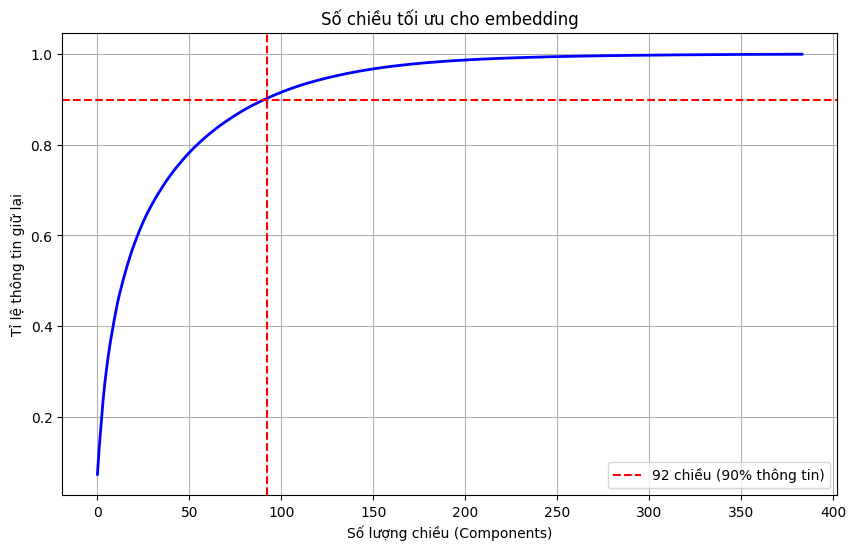

Số chiều đạt 90% variance: 92


In [16]:
from sklearn.decomposition import PCA

pca_full = PCA()
pca_full.fit(X_text_train)

cumsum = np.cumsum(pca_full.explained_variance_ratio_)
d_90 = int(np.argmax(cumsum >= 0.90) + 1)

plt.figure(figsize=(10, 6))
plt.plot(cumsum, linewidth=2, color='b')
plt.axvline(x=d_90, color='r', linestyle='--', label=f'{d_90} chiều (90% thông tin)')
plt.axhline(y=0.90, color='r', linestyle='--')
plt.xlabel('Số lượng chiều (Components)')
plt.ylabel('Tỉ lệ thông tin giữ lại')
plt.title('Số chiều tối ưu cho embedding')
plt.legend(); plt.grid(True); plt.show()

print(f'Số chiều đạt 90% variance: {d_90}')

In [19]:
N_COMPONENTS = 92

pca_text = PCA(n_components=N_COMPONENTS, random_state=42)
X_text_pca_train = pca_text.fit_transform(X_text_train)
X_text_pca_test  = pca_text.transform(X_text_test)

var_kept = pca_text.explained_variance_ratio_.sum()
print(f'PCA giữ {var_kept*100:.2f}% variance với {N_COMPONENTS} chiều')
print('X_text_pca_train:', X_text_pca_train.shape)
print('X_text_pca_test :', X_text_pca_test.shape)

PCA giữ 90.05% variance với 92 chiều
X_text_pca_train: (453686, 92)
X_text_pca_test : (56818, 92)


## 6. Lưu artifact cho notebook clustering

In [20]:
import os, joblib
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

np.save(f'{DATA_DIR}/X_text_pca_train.npy', X_text_pca_train)
np.save(f'{DATA_DIR}/X_text_pca_test.npy',  X_text_pca_test)
joblib.dump(pca_text, f'{MODEL_DIR}/pca_text.joblib')

# Bỏ cột full_text trước khi lưu để file nhẹ hơn (có thể tạo lại từ 3 cột gốc)
Train.drop(columns=['full_text']).to_parquet(f'{DATA_DIR}/train_processed.parquet', index=False)
Test.drop(columns=['full_text']).to_parquet(f'{DATA_DIR}/test_processed.parquet',  index=False)

print('Đã lưu:')
print(' -', f'{DATA_DIR}/X_text_pca_train.npy', X_text_pca_train.shape)
print(' -', f'{DATA_DIR}/X_text_pca_test.npy',  X_text_pca_test.shape)
print(' -', f'{MODEL_DIR}/pca_text.joblib')
print(' -', f'{DATA_DIR}/train_processed.parquet')
print(' -', f'{DATA_DIR}/test_processed.parquet')

Đã lưu:
 - ../data/clean/X_text_pca_train.npy (453686, 92)
 - ../data/clean/X_text_pca_test.npy (56818, 92)
 - ../models/pca_text.joblib
 - ../data/clean/train_processed.parquet
 - ../data/clean/test_processed.parquet
